# CSCI461 Assignment 1 - Dockerized Data, Text Analysis and Machine Learning

**Dataset:** SMS Spam Collection (UCI Machine Learning Repository, dataset #228)
<https://archive.ics.uci.edu/dataset/228/sms+spam+collection> - licensed CC BY 4.0.

**Pipeline:** Dockerfile -> Custom Image -> Container -> Jupyter -> Data Cleaning -> Sampling -> Text Analysis -> TF-IDF -> Classification + K-Means -> Persistent Outputs -> Docker Hub

This notebook runs inside the custom Docker container. Every file it writes goes to `output/`,
which is bind-mounted to the host so results survive after the container is removed.

| Section | Assignment part |
|---|---|
| 1 | Setup |
| 2 | Dataset understanding |
| 3 | Missing values and duplicates |
| 4 | `loc` / `iloc` |
| 5 | Transformations and feature creation |
| 6 | Sampling (simple random, stratified, cluster) |
| 7 | Correlation of numerical text features |
| 8 | Text analysis |
| 9 | Supervised text classification (TF-IDF + Naive Bayes) |
| 10 | Bonus - model extension (2 classifiers + n-grams + tuning) |
| 11 | K-Means clustering |
| 12 | Save outputs and conclusion |

## 1. Setup

In [1]:
import re
import string
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import MinMaxScaler, Normalizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             silhouette_score, adjusted_rand_score)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# The notebook may be started from the project root or from notebook/, so find the root.
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH = ROOT / "data" / "dataset.csv"
OUT_DIR = ROOT / "output"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    path = FIG_DIR / name
    plt.savefig(path, dpi=120, bbox_inches="tight")
    print("saved ->", path.relative_to(ROOT))

print("project root :", ROOT)
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

project root : /home/jovyan/bd-a1
pandas 3.1.0 | numpy 2.5.4 | scikit-learn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2


## 2. Dataset understanding

The original UCI file is tab-separated (`label<TAB>message`). It was converted once on the host to
`data/dataset.csv` with two columns: `label` and `message`.

In [2]:
df_raw = pd.read_csv(DATA_PATH, encoding="utf-8")
df_raw.head(10)

,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"
5,spam,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...
6,ham,Even my brother is not like to speak with me. They treat me like aids patent.
7,ham,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Calle...
8,spam,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 0906170146...
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call Th...


In [3]:
print("shape  :", df_raw.shape)
print("columns:", list(df_raw.columns))
print("\ndtypes:")
print(df_raw.dtypes)

shape  : (5574, 2)
columns: ['label', 'message']

dtypes:
label      str
message    str
dtype: object


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5574 non-null   str  
 1   message  5574 non-null   str  
dtypes: str(2)
memory usage: 543.0 KB


In [5]:
# Descriptive statistics for the object columns
df_raw.describe(include="all")

,label,message
count,5574,5574
unique,2,5171
top,ham,"Sorry, I'll call later"
freq,4827,30


In [6]:
# Descriptive statistics of message length (the raw data has no numeric column yet)
df_raw["message"].str.len().describe().to_frame("message_char_length")

,message_char_length
count,5574.000000
mean,80.478292
std,59.848302
min,2.000000
25%,36.000000
50%,62.000000
75%,122.000000
max,910.000000


In [7]:
print("Class counts:")
print(df_raw["label"].value_counts())
print("\nClass proportions:")
print(df_raw["label"].value_counts(normalize=True).round(4))

Class counts:
label
ham     4827
spam     747
Name: count, dtype: int64

Class proportions:
label
ham     0.866
spam    0.134
Name: proportion, dtype: float64


**What one row represents:** one SMS message sent to a mobile phone, together with a human label
saying whether it is `spam` (unwanted advertising / scam) or `ham` (a normal, legitimate message).

**Column roles**

| Column | Role | Notes |
|---|---|---|
| `message` | **text** column | Free text of the SMS (raw, unchanged) |
| `label` | **label / category** column | Two classes: `ham`, `spam` - imbalanced (about 87% ham, 13% spam) |
| *(none)* | numerical columns | The raw data has **no** numerical columns. Numerical features such as `char_count`, `word_count`, `unique_word_count`, `avg_word_length`, `digit_count` are created from the text in Section 5. |

## 3. Missing values and duplicates

In [8]:
print("Missing values per column:")
print(df_raw.isna().sum())
blank = df_raw["message"].fillna("").str.strip().eq("").sum()
print("\nEmpty / whitespace-only messages:", blank)
print("Unexpected labels:", sorted(set(df_raw["label"].unique()) - {"ham", "spam"}))

Missing values per column:
label      0
message    0
dtype: int64

Empty / whitespace-only messages: 0
Unexpected labels: []


In [9]:
dup_rows = df_raw.duplicated(keep="first")
dup_msgs = df_raw.duplicated(subset="message", keep="first")
print("Fully duplicated rows (label + message):", dup_rows.sum())
print("Duplicated message text (any label)     :", dup_msgs.sum())

# Same text with different labels would be a labelling conflict
conflicts = df_raw.groupby("message")["label"].nunique()
print("Messages that appear with BOTH labels    :", (conflicts > 1).sum())

print("\nDuplicates by class:")
print(df_raw[dup_rows]["label"].value_counts())
print("\nMost repeated messages:")
df_raw["message"].value_counts().head(5)

Fully duplicated rows (label + message): 403
Duplicated message text (any label)     : 403
Messages that appear with BOTH labels    : 0

Duplicates by class:
label
ham     309
spam     94
Name: count, dtype: int64

Most repeated messages:


message
Sorry, I'll call later                                                                                                                                                                 30
I cant pick the phone right now. Pls send a message                                                                                                                                    12
Ok...                                                                                                                                                                                  10
Please call our customer service representative on FREEPHONE 0808 145 4742 between 9am-11pm as you have WON a guaranteed £1000 cash or £5000 prize!                                     4
Wen ur lovable bcums angry wid u, dnt take it seriously.. Coz being angry is d most childish n true way of showing deep affection, care n luv!.. kettoda manda... Have nice day da.     4
Name: count, dtype: int64

**Treatment and justification**

* **Missing values:** there are no missing values or empty messages, so no imputation is needed.
  The text cleaning function in Section 8 still handles missing text defensively (`NaN` -> `""`).
* **Duplicates:** 403 rows are exact copies (same label and same text): 309 ham - mostly short
  automatic replies such as "Sorry, I'll call later" (30 copies) - and 94 spam from repeated campaigns. We **drop exact duplicates
  and keep the first copy** because:
  1. they over-weight a few messages in word frequencies and statistics;
  2. the same message could land in both the training and the test set, which leaks information and
     makes the classifier look better than it really is;
  3. no message has conflicting labels, so dropping duplicates does not lose any label information.
* Labels are standardised (stripped, lowercase) and whitespace at the ends of messages is removed.

In [10]:
print("Shape BEFORE cleaning:", df_raw.shape)

df = df_raw.copy()
df["label"] = df["label"].str.strip().str.lower()
df["message"] = df["message"].fillna("").str.strip()
df = df[df["message"] != ""]
print("Duplicates after trimming whitespace:", df.duplicated(subset=["label", "message"]).sum(),
      "(403 exact + messages that differed only by leading/trailing spaces)")
df = df.drop_duplicates(subset=["label", "message"], keep="first").reset_index(drop=True)

print("Shape AFTER cleaning :", df.shape)
print("Rows removed         :", len(df_raw) - len(df))
print("\nClass proportions after cleaning:")
print(df["label"].value_counts(normalize=True).round(4))

Shape BEFORE cleaning: (5574, 2)
Duplicates after trimming whitespace: 414 (403 exact + messages that differed only by leading/trailing spaces)
Shape AFTER cleaning : (5160, 2)
Rows removed         : 414

Class proportions after cleaning:
label
ham     0.8756
spam    0.1244
Name: proportion, dtype: float64


## 4. Selecting data with `loc` and `iloc`

In [11]:
# loc: meaningful conditional selection (label-based)
# -> long spam messages (> 150 characters) that mention "free": typical prize / offer spam
long_free_spam = df.loc[(df["label"] == "spam") &
                        (df["message"].str.len() > 150) &
                        (df["message"].str.contains("free", case=False)),
                        ["label", "message"]]
print("Long spam messages that mention 'free':", len(long_free_spam))
long_free_spam.head()

Long spam messages that mention 'free': 87


,label,message
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call Th...
12,spam,"URGENT! You have won a 1 week FREE membership in our £100,000 Prize Jackpot! Txt the word: CLAIM to No: 81010 T&C ww..."
42,spam,07732584351 - Rodger Burns - MSG = We tried to call you re your reply to our sms for a free nokia mobile + free camc...
56,spam,"Congrats! 1 year special cinema pass for 2 is yours. call 09061209465 now! C Suprman V, Matrix3, StarWars3, etc all ..."


In [12]:
# loc with a row range and a column list (loc ranges include the end label)
df.loc[10:14, ["label", "message"]]

,label,message
10,ham,"I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k? I've cried enough today."
11,spam,"SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs a..."
12,spam,"URGENT! You have won a 1 week FREE membership in our £100,000 Prize Jackpot! Txt the word: CLAIM to No: 81010 T&C ww..."
13,ham,I've been searching for the right words to thank you for this breather. I promise i wont take your help for granted ...
14,ham,I HAVE A DATE ON SUNDAY WITH WILL!!


In [13]:
# iloc: positional selection - first 5 rows, both columns
df.iloc[0:5, 0:2]

,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


In [14]:
# iloc with np.r_ : rows 0-2, rows 100-102 and the last 3 rows in a single selection
df.iloc[np.r_[0:3, 100:103, -3:0], :]

,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
100,ham,Please don't text me anymore. I have nothing else to say.
101,ham,Okay name ur price as long as its legal! Wen can I pick them up? Y u ave x ams xx
102,ham,I'm still looking for a car to buy. And have not gone 4the driving test yet.
5157,ham,"Pity, * was in mood for that. So...any other suggestions?"
5158,ham,The guy did some bitching but I acted like i'd be interested in buying something else next week and he gave it to us...
5159,ham,Rofl. Its true to its name


## 5. Transformations and feature creation

We apply the following transformations:

1. **Type conversion** - `label` from `object` to `category` (smaller, explicit set of values).
2. **Encoding** - `label_num`: ham = 0, spam = 1 (needed for correlation and models).
3. **Feature creation** - numerical text features: `char_count`, `word_count`, `unique_word_count`,
   `avg_word_length`, `digit_count`, `uppercase_ratio`, `punct_count`, plus flags `has_url`, `has_currency`.
4. **Binning** - `length_bin`: message length grouped into `very short / short / medium / long`.
5. **Normalization** - `char_count_minmax`: min-max scaling of `char_count` to the range [0, 1].

In [15]:
# 1) type conversion
df["label"] = df["label"].astype("category")

# 2) encoding
df["label_num"] = df["label"].map({"ham": 0, "spam": 1}).astype(int)

# 3) feature creation
words = df["message"].str.split()
df["char_count"] = df["message"].str.len()
df["word_count"] = words.str.len()
df["unique_word_count"] = words.apply(lambda w: len(set(x.lower() for x in w)))
df["avg_word_length"] = words.apply(lambda w: np.mean([len(x) for x in w]) if w else 0.0).round(3)
df["digit_count"] = df["message"].str.count(r"\d")
df["uppercase_ratio"] = (df["message"].str.count(r"[A-Z]") / df["char_count"]).round(4)
df["punct_count"] = df["message"].apply(lambda s: sum(ch in string.punctuation for ch in s))
df["has_url"] = df["message"].str.contains(r"http|www\.|\.com", case=False, regex=True).astype(int)
df["has_currency"] = df["message"].str.contains(r"£|\$|€|pounds?|cash|prize", case=False, regex=True).astype(int)

# 4) binning
df["length_bin"] = pd.cut(df["char_count"], bins=[0, 40, 80, 160, np.inf],
                          labels=["very short (<=40)", "short (41-80)", "medium (81-160)", "long (>160)"])

# 5) normalization
df["char_count_minmax"] = MinMaxScaler().fit_transform(df[["char_count"]]).round(4)

print(df.dtypes)
df.head()

label                category
message                   str
label_num               int64
char_count              int64
word_count              int64
unique_word_count       int64
avg_word_length       float64
digit_count             int64
uppercase_ratio       float64
punct_count             int64
has_url                 int64
has_currency            int64
length_bin           category
char_count_minmax     float64
dtype: object


,label,message,label_num,char_count,word_count,unique_word_count,avg_word_length,digit_count,uppercase_ratio,punct_count,has_url,has_currency,length_bin,char_count_minmax
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",0,111,20,20,4.600,0,0.0270,9,0,0,medium (81-160),0.1200
1,ham,Ok lar... Joking wif u oni...,0,29,6,6,4.000,0,0.0690,6,0,0,very short (<=40),0.0297
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,1,155,28,24,4.571,25,0.0645,6,0,0,medium (81-160),0.1685
3,ham,U dun say so early hor... U c already then say...,0,49,11,10,3.545,0,0.0408,6,0,0,short (41-80),0.0518
4,ham,"Nah I don't think he goes to usf, he lives around here though",0,61,13,12,3.769,0,0.0328,2,0,0,short (41-80),0.0650


In [16]:
# Effect of the binning: share of spam in each length bin
pd.crosstab(df["length_bin"], df["label"], normalize="index").round(3)

label,ham,spam
length_bin,,
very short (<=40),0.994,0.006
short (41-80),0.976,0.024
medium (81-160),0.684,0.316
long (>160),0.793,0.207


In [17]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
label_num,5160.0,0.124,0.330,0.0,0.000,0.000,0.000,1.0
char_count,5160.0,79.140,58.289,2.0,36.000,61.000,118.000,910.0
word_count,5160.0,15.411,11.103,1.0,7.000,12.000,22.000,171.0
unique_word_count,5160.0,14.246,9.064,1.0,7.000,12.000,20.000,100.0
avg_word_length,5160.0,4.252,1.143,1.5,3.667,4.091,4.643,49.0
digit_count,5160.0,2.181,5.987,0.0,0.000,0.000,1.000,47.0
uppercase_ratio,5160.0,0.063,0.111,0.0,0.025,0.036,0.056,1.0
punct_count,5160.0,4.073,4.420,0.0,1.000,3.000,6.000,133.0
has_url,5160.0,0.022,0.148,0.0,0.000,0.000,0.000,1.0
has_currency,5160.0,0.055,0.228,0.0,0.000,0.000,0.000,1.0


## 6. Sampling

We draw about 20% of the cleaned data in three different ways and compare the class distribution
of each sample with the full data.

* **Simple random sampling (SRS):** every message has the same chance of being chosen.
* **Stratified sampling:** sample 20% *inside each class* separately, so the spam/ham proportion
  is kept exactly.
* **Cluster sampling:** split the data into 50 groups (clusters) of consecutive messages, then pick
  10 whole clusters at random and keep *every* message in them. Cheap to collect in practice
  (e.g. take all messages from a few phones / days), but less representative.

In [18]:
FRAC = 0.20

# Simple random sampling
srs = df.sample(frac=FRAC, random_state=RANDOM_STATE)

# Stratified sampling (20% of each class)
strat = df.groupby("label", group_keys=False, observed=True).sample(frac=FRAC, random_state=RANDOM_STATE)

# Cluster sampling: 50 clusters of consecutive rows, choose 10 whole clusters
N_CLUSTERS, N_CHOSEN = 50, 10
df["sample_cluster"] = np.arange(len(df)) * N_CLUSTERS // len(df)
rng = np.random.default_rng(RANDOM_STATE)
chosen = rng.choice(N_CLUSTERS, size=N_CHOSEN, replace=False)
clus = df[df["sample_cluster"].isin(chosen)]
print("Chosen clusters:", sorted(chosen.tolist()))

def dist(d):
    return d["label"].value_counts(normalize=True).reindex(["ham", "spam"])

sampling_cmp = pd.DataFrame({
    "original": dist(df),
    "simple_random": dist(srs),
    "stratified": dist(strat),
    "cluster": dist(clus),
}).T
sampling_cmp["n_rows"] = [len(df), len(srs), len(strat), len(clus)]
sampling_cmp["spam_diff_vs_original (pp)"] = ((sampling_cmp["spam"] - sampling_cmp.loc["original", "spam"]) * 100).round(2)
sampling_cmp.round(4)

Chosen clusters: [3, 4, 9, 19, 28, 32, 33, 39, 44, 49]


label,ham,spam,n_rows,spam_diff_vs_original (pp)
original,0.8756,0.1244,5160,0.00
simple_random,0.8876,0.1124,1032,-1.20
stratified,0.8760,0.1240,1032,-0.04
cluster,0.8874,0.1126,1030,-1.18


saved -> output/figures/sampling_comparison.png


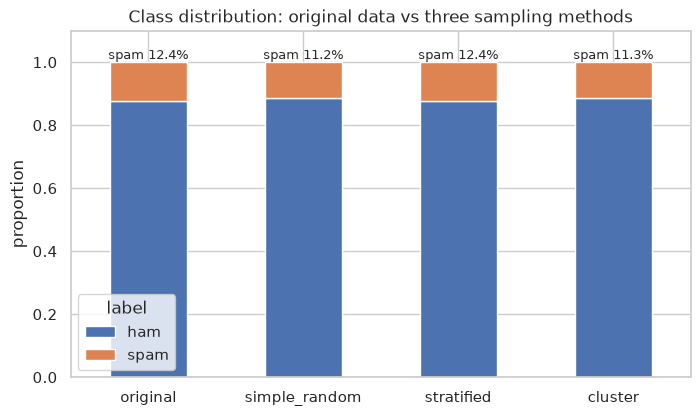

In [19]:
ax = sampling_cmp[["ham", "spam"]].plot(kind="bar", stacked=True, figsize=(8, 4.5), color=["#4C72B0", "#DD8452"])
for i, v in enumerate(sampling_cmp["spam"]):
    ax.text(i, 1.01, f"spam {v:.1%}", ha="center", fontsize=9)
ax.set_ylim(0, 1.1)
ax.set_ylabel("proportion")
ax.set_title("Class distribution: original data vs three sampling methods")
plt.xticks(rotation=0)
save_fig("sampling_comparison.png")
plt.show()

In [20]:
# One sample can be lucky or unlucky, so repeat each method 300 times with different seeds
# and look at how much the spam share moves around (standard deviation).
def one_round(seed):
    r = np.random.default_rng(seed)
    s1 = df.sample(frac=FRAC, random_state=seed)
    s2 = df.groupby("label", group_keys=False, observed=True).sample(frac=FRAC, random_state=seed)
    s3 = df[df["sample_cluster"].isin(r.choice(N_CLUSTERS, size=N_CHOSEN, replace=False))]
    return [d["label_num"].mean() for d in (s1, s2, s3)]

reps = pd.DataFrame([one_round(s) for s in range(300)], columns=["simple_random", "stratified", "cluster"])
variability = pd.DataFrame({
    "mean spam share": reps.mean(),
    "std (pp)": reps.std() * 100,
    "min": reps.min(),
    "max": reps.max(),
}).round(4)
print("Original spam share:", round(df["label_num"].mean(), 4))
variability

Original spam share: 0.1244


,mean spam share,std (pp),min,max
simple_random,0.1246,0.9163,0.0969,0.1492
stratified,0.1240,0.0000,0.1240,0.1240
cluster,0.1234,0.9239,0.1008,0.1530


**Comparison of the three methods** (original spam share = 12.44%)

| Method | One sample (seed 42) | 300 repeats: std of spam share |
|---|---|---|
| Simple random | 11.24% (-1.20 pp) | 0.92 pp |
| Stratified | 12.40% (-0.04 pp) | 0.00 pp |
| Cluster (10 of 50 blocks) | 11.26% (-1.18 pp) | 0.92 pp |

* **Stratified** sampling keeps the class proportion *exactly* every time (std = 0), because it samples
  each class separately. It is the best choice for an imbalanced label like ours (only ~12% spam), and it is
  the same idea we use later with `stratify=` in the train/test split.
* **Simple random** sampling is unbiased on average (mean 12.46% over 300 repeats) but any single sample can
  drift; with seed 42 it under-represents spam by 1.2 percentage points, and over the repeats it ranged from
  9.7% to 14.9%.
* **Cluster** sampling picks whole blocks of rows. Here it behaves similarly to simple random sampling
  (std 0.92 pp), because the file order is almost random with respect to the label - spam is spread
  evenly across the blocks. If clusters were *homogeneous* (for example all messages from one phone, or one
  spam campaign per block) cluster sampling would have a much larger error, because the effective sample size
  is the number of clusters (10), not the number of messages. Its advantage is lower collection cost,
  not accuracy.


## 7. Correlation of numerical text features
We use the numerical text features created in Section 5 plus the encoded label (`label_num`).

saved -> output/figures/correlation_heatmap.png


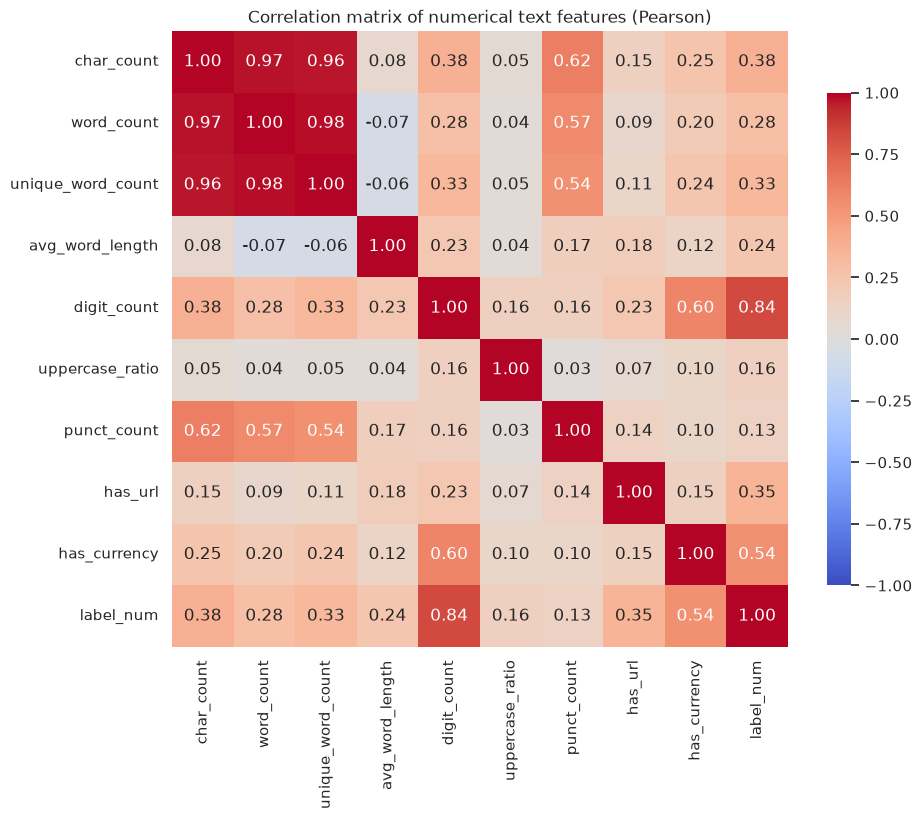

In [21]:
num_cols = ["char_count", "word_count", "unique_word_count", "avg_word_length",
            "digit_count", "uppercase_ratio", "punct_count", "has_url", "has_currency", "label_num"]
corr = df[num_cols].corr(method="pearson")

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .8})
plt.title("Correlation matrix of numerical text features (Pearson)")
save_fig("correlation_heatmap.png")
plt.show()

In [22]:
# Strongest and weakest pairs (upper triangle only)
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename("r").reset_index()
             .rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
pairs["abs_r"] = pairs["r"].abs()
print("Strongest relationships:")
display(pairs.sort_values("abs_r", ascending=False).head(6).round(3))
print("Weakest relationships:")
display(pairs.sort_values("abs_r").head(6).round(3))
print("Correlation of each feature with the spam label:")
corr["label_num"].drop("label_num").sort_values(ascending=False).round(3)

Strongest relationships:


,feature_1,feature_2,r,abs_r
12,word_count,unique_word_count,0.981,0.981
1,char_count,word_count,0.974,0.974
2,char_count,unique_word_count,0.964,0.964
49,digit_count,label_num,0.835,0.835
6,char_count,punct_count,0.621,0.621
48,digit_count,has_currency,0.599,0.599


Weakest relationships:


,feature_1,feature_2,r,abs_r
56,uppercase_ratio,punct_count,0.030,0.030
15,word_count,uppercase_ratio,0.036,0.036
35,avg_word_length,uppercase_ratio,0.040,0.040
25,unique_word_count,uppercase_ratio,0.047,0.047
5,char_count,uppercase_ratio,0.054,0.054
23,unique_word_count,avg_word_length,-0.060,0.060


Correlation of each feature with the spam label:


digit_count          0.835
has_currency         0.545
char_count           0.377
has_url              0.353
unique_word_count    0.334
word_count           0.281
avg_word_length      0.240
uppercase_ratio      0.157
punct_count          0.133
Name: label_num, dtype: float64

**Interpretation**

* **Very strong positive (r > 0.95):** `char_count`, `word_count` and `unique_word_count`
  (word_count-unique_word_count r = 0.98, char_count-word_count r = 0.97). Longer messages simply contain more
  words and more distinct words, so these three features carry almost the same information; using all of them
  in a linear model would cause multicollinearity.
* **Strong relationship with the label:** `digit_count` is by far the strongest single indicator of spam
  (r = 0.84), followed by `has_currency` (0.54). `digit_count` and `has_currency` are also related to each
  other (0.60): prices and phone numbers appear together in offers.
* **Moderate:** `char_count` (0.38), `has_url` (0.35) and `unique_word_count` (0.33) with the label; `punct_count`
  with length (0.62) - longer messages have more punctuation.
* **Weak (|r| < 0.1):** `uppercase_ratio` with almost everything (e.g. 0.03 with `punct_count`, 0.04 with
  `word_count`) and `avg_word_length` with the length features (-0.06 to 0.08). Average word length does not
  depend on how long a message is.

**Correlation does not imply causation.** The high correlation between `digit_count` and spam does not mean
that adding digits *makes* a message spam, or that removing them would make spam legitimate. Both are caused by
a third factor - the sender's intention to sell something, which requires a phone number, short code or
price. Pearson correlation only measures how two variables move together linearly; it cannot tell the
direction of the effect, it can be produced by hidden confounders or by chance, and it misses non-linear
relationships. A causal claim would need a controlled experiment.


*Next: Section 8 - Text analysis (work in progress).*